## Lab objectives

The aim of this lab is to investigate how Singular Value Decomposition (SVD) can be used to represent and compress images. Each grayscale image is treated as a matrix of pixel intensities. SVD decomposes this matrix into three matrices: the left singular vectors, the singular values, and the right singular vectors.

The singular values are ordered from the largest to the smallest. The largest values usually contain the most important large-scale image information, while smaller values contribute progressively finer details. By keeping only selected singular-value components, we can create an approximation of the original image.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [2]:
image_path = "photo.jpg"
img = Image.open(image_path)
imggray = img.convert('L')

Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

Mark how we have used the command $matrix$ to generate a matrix from the image!

C:\Users\Dell\AppData\Local\Temp\ipykernel_13984\689796363.py:1: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  imgmat = np.array(list(imggray.getdata(band=0)), float)
C:\Users\Dell\AppData\Local\Temp\ipykernel_13984\689796363.py:2: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  imgmat.shape = (imggray.size[1], imggray.size[0])


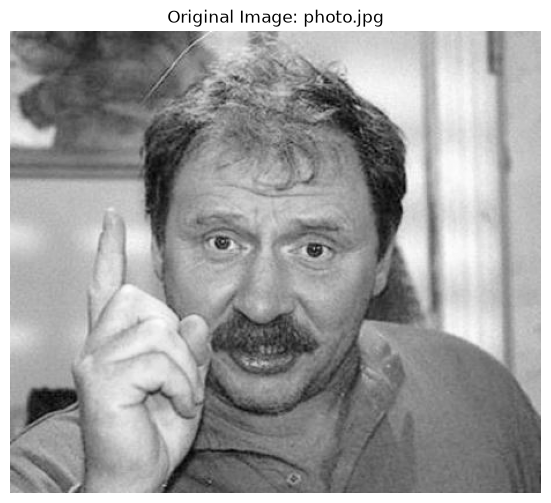

In [4]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)

plt.figure(figsize=(9, 6))
plt.imshow(imgmat, cmap='gray')
plt.title(f"Original Image: {image_path}")
plt.axis('off')
plt.show()



We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

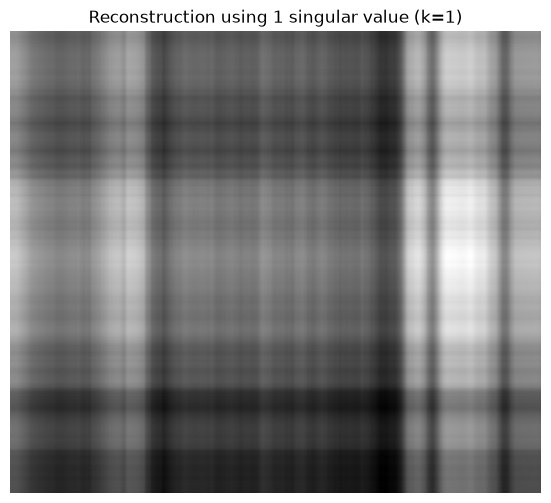

In [6]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.figure(figsize=(9, 6))
plt.imshow(reconstimg, cmap='gray')
plt.title("Reconstruction using 1 singular value (k=1)")
plt.axis('off')
plt.show()

## Observation: reconstruction with one singular value

The reconstruction using only the largest singular value preserves only a simplified version of the image. It may retain broad brightness patterns and large-scale structure, but most edges, textures, and fine details are lost.

This demonstrates that a single singular-value component is not sufficient for a visually accurate reconstruction. More components are needed to represent the variation and detail present in the original image.


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

U shape: (400, 400)
Sigma shape: (400,)
V shape: (460, 460)


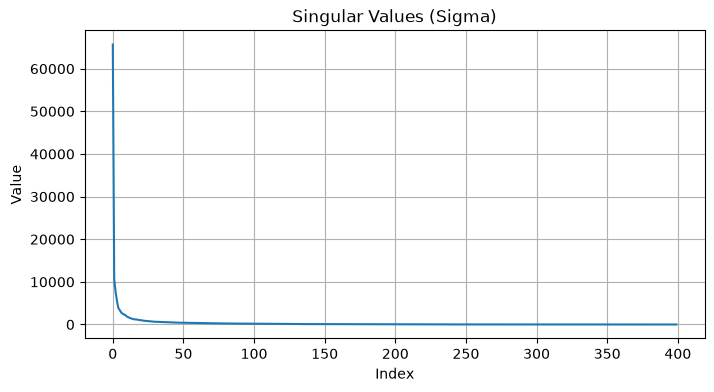

In [7]:
print("U shape:", U.shape)
print("Sigma shape:", sigma.shape)
print("V shape:", V.shape)

plt.figure(figsize=(8, 4))
plt.plot(sigma)
plt.title("Singular Values (Sigma)")
plt.xlabel("Index")
plt.ylabel("Value")
plt.grid(True)
plt.show()

## Observation: singular values and image quality

The singular values are arranged in descending order. Typically, the first few values are considerably larger than the later ones, and their magnitudes gradually decrease. This means that the first components account for a substantial part of the image information.

A reasonable value of *k* depends on the image and on the required visual quality. A small *k* can preserve the general structure, while a larger *k* is needed to retain textures and sharp details. The cumulative-energy results and the reconstruction examples below provide a more objective way to compare different values of *k*.

**Important:** singular values are not eigenvalues, although they are closely related to the eigenvalues of the matrix products \(A^T A\) and \(AA^T\).

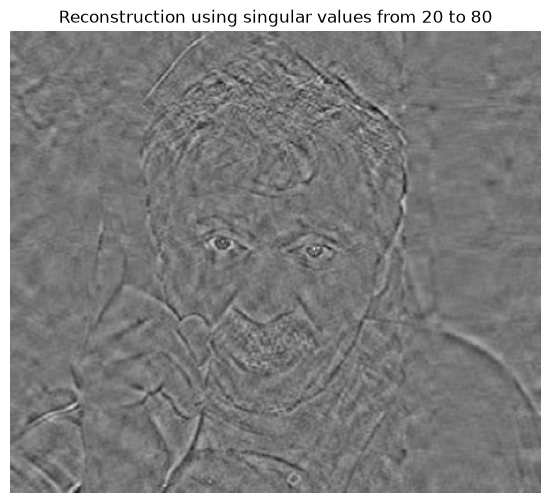

In [9]:
i = 80
j = 20
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])

plt.figure(figsize=(9, 6))
plt.imshow(reconstimg, cmap='gray')
plt.title(f"Reconstruction using singular values from {j} to {i}")
plt.axis('off')
plt.show()

## Experiment: using components 20 to 80

In this experiment, the reconstruction uses singular-value components from index 20 up to (but not including) index 80. The largest 20 components are excluded, as are all components from index 80 onward.

This reconstruction does not usually improve the image. The largest components contain much of the global structure and low-frequency information, so removing them can make the result less recognizable. The selected middle components may still represent some edges and textures, but they do not replace the information carried by the leading components.

Therefore, using components 10, 11, …, *k*+10 is generally not expected to produce a better overall reconstruction than using the first *k* components. It can emphasize different details, but it discards the most significant components. The visual result should be compared with the reconstruction using components 1 to *k*.

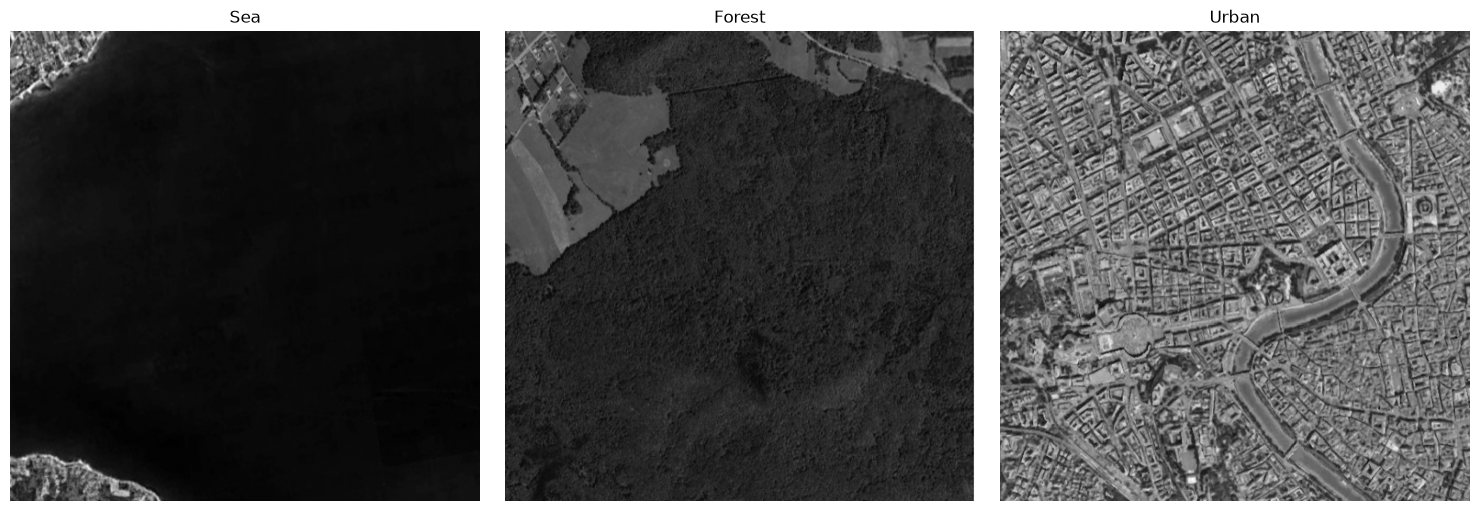

In [17]:
terrain_files = {
    "Sea": "see.jpg",
    "Forest": "forest.jpg",
    "Urban": "town.jpg",
}

SIZE = (512, 512)
terrains = {}

for name, filename in terrain_files.items():
    img = Image.open(filename).convert("L").resize(SIZE)
    terrains[name] = np.array(img, dtype=float)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, matrix) in zip(axes, terrains.items()):
    ax.imshow(matrix, cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()


## Satellite images representing different terrain types

Three grayscale images are used to compare how SVD represents different landscape patterns:

- **Sea:** generally contains broad, relatively smooth regions, although waves, coastal features, and shadows may add texture.
- **Forest:** often contains irregular and fine-scale textures caused by vegetation and variations in canopy structure.
- **Urban area:** contains buildings, roads, boundaries, and other geometric features that can create strong edges and local contrast.

All images are resized to the same dimensions so that their SVD results can be compared under the same image size. Converting them to grayscale allows each image to be represented as a two-dimensional matrix of pixel intensities.

In [18]:
results = {}

for name, matrix in terrains.items():
    U_t, s_t, Vt_t = np.linalg.svd(matrix, full_matrices=False)
    energy_t = np.cumsum(s_t**2) / np.sum(s_t**2)
    results[name] = {
        "U": U_t,
        "sigma": s_t,
        "Vt": Vt_t,
        "energy": energy_t,
    }


## SVD decomposition and cumulative energy

SVD is calculated independently for each terrain image. The cumulative energy is computed as the cumulative sum of squared singular values divided by the sum of all squared singular values.

Cumulative energy indicates how much of the matrix's total squared magnitude is represented by the first *k* components. It is useful for comparing compression levels, but it is not identical to human visual perception: two images with the same energy percentage may not look equally detailed.

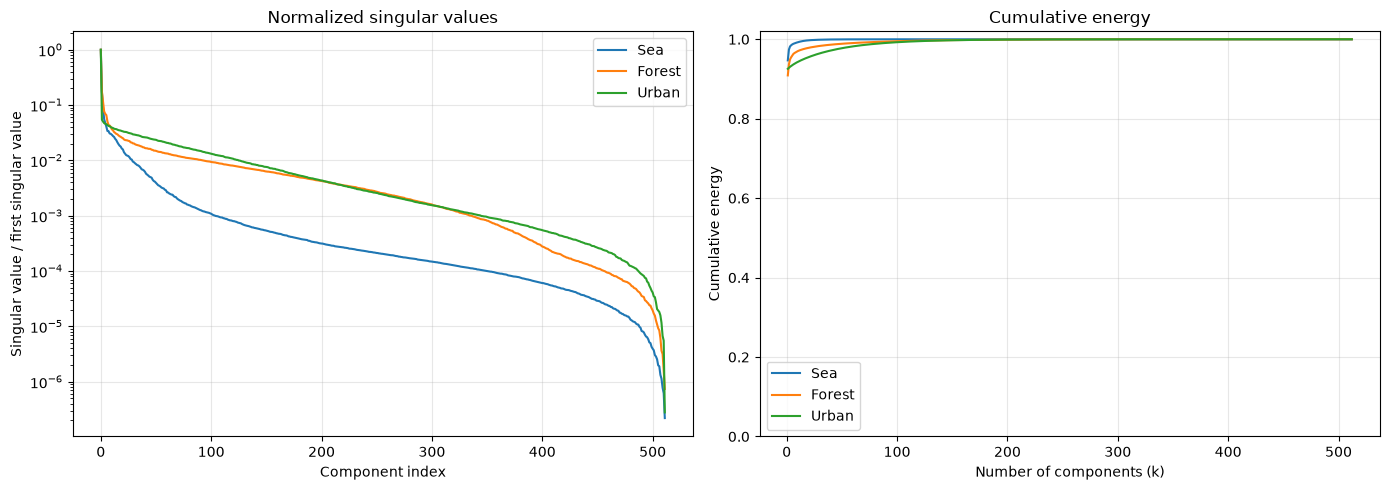

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, result in results.items():
    normalized_sigma = result["sigma"] / result["sigma"][0]
    axes[0].semilogy(normalized_sigma, label=name)
    axes[1].plot(np.arange(1, len(result["energy"]) + 1),
                 result["energy"], label=name)

axes[0].set_title("Normalized singular values")
axes[0].set_xlabel("Component index")
axes[0].set_ylabel("Singular value / first singular value")

axes[1].set_title("Cumulative energy")
axes[1].set_xlabel("Number of components (k)")
axes[1].set_ylabel("Cumulative energy")
axes[1].set_ylim(0, 1.02)

for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [20]:
print(f"{'Terrain':<12}{'90% energy':>14}{'95% energy':>14}{'99% energy':>14}")
for name, result in results.items():
    energy = result["energy"]
    counts = [int(np.argmax(energy >= threshold) + 1)
              for threshold in (0.90, 0.95, 0.99)]
    print(f"{name:<12}{counts[0]:>14}{counts[1]:>14}{counts[2]:>14}")


Terrain         90% energy    95% energy    99% energy
Sea                      1             2             8
Forest                   1             4            57
Urban                    1            16            87


## Observation: how many components are sufficient?

The table reports the number of singular-value components required to reach 90%, 95%, and 99% cumulative energy for each terrain image.

A lower component count means that the image's matrix energy is concentrated in fewer SVD components, making it more compact in this representation. A higher count indicates that more components are needed to reach the same energy threshold.

The 90% threshold provides a more compact approximation, while 95% and especially 99% retain more of the matrix energy. The reconstruction plots should be considered together with this table to judge whether the remaining visual differences are noticeable.

The exact number of components is image-dependent. It should be taken from the printed table rather than assumed in advance.

Available images: ['Sea', 'Forest', 'Urban']
Available SVD results: ['Sea', 'Forest', 'Urban']


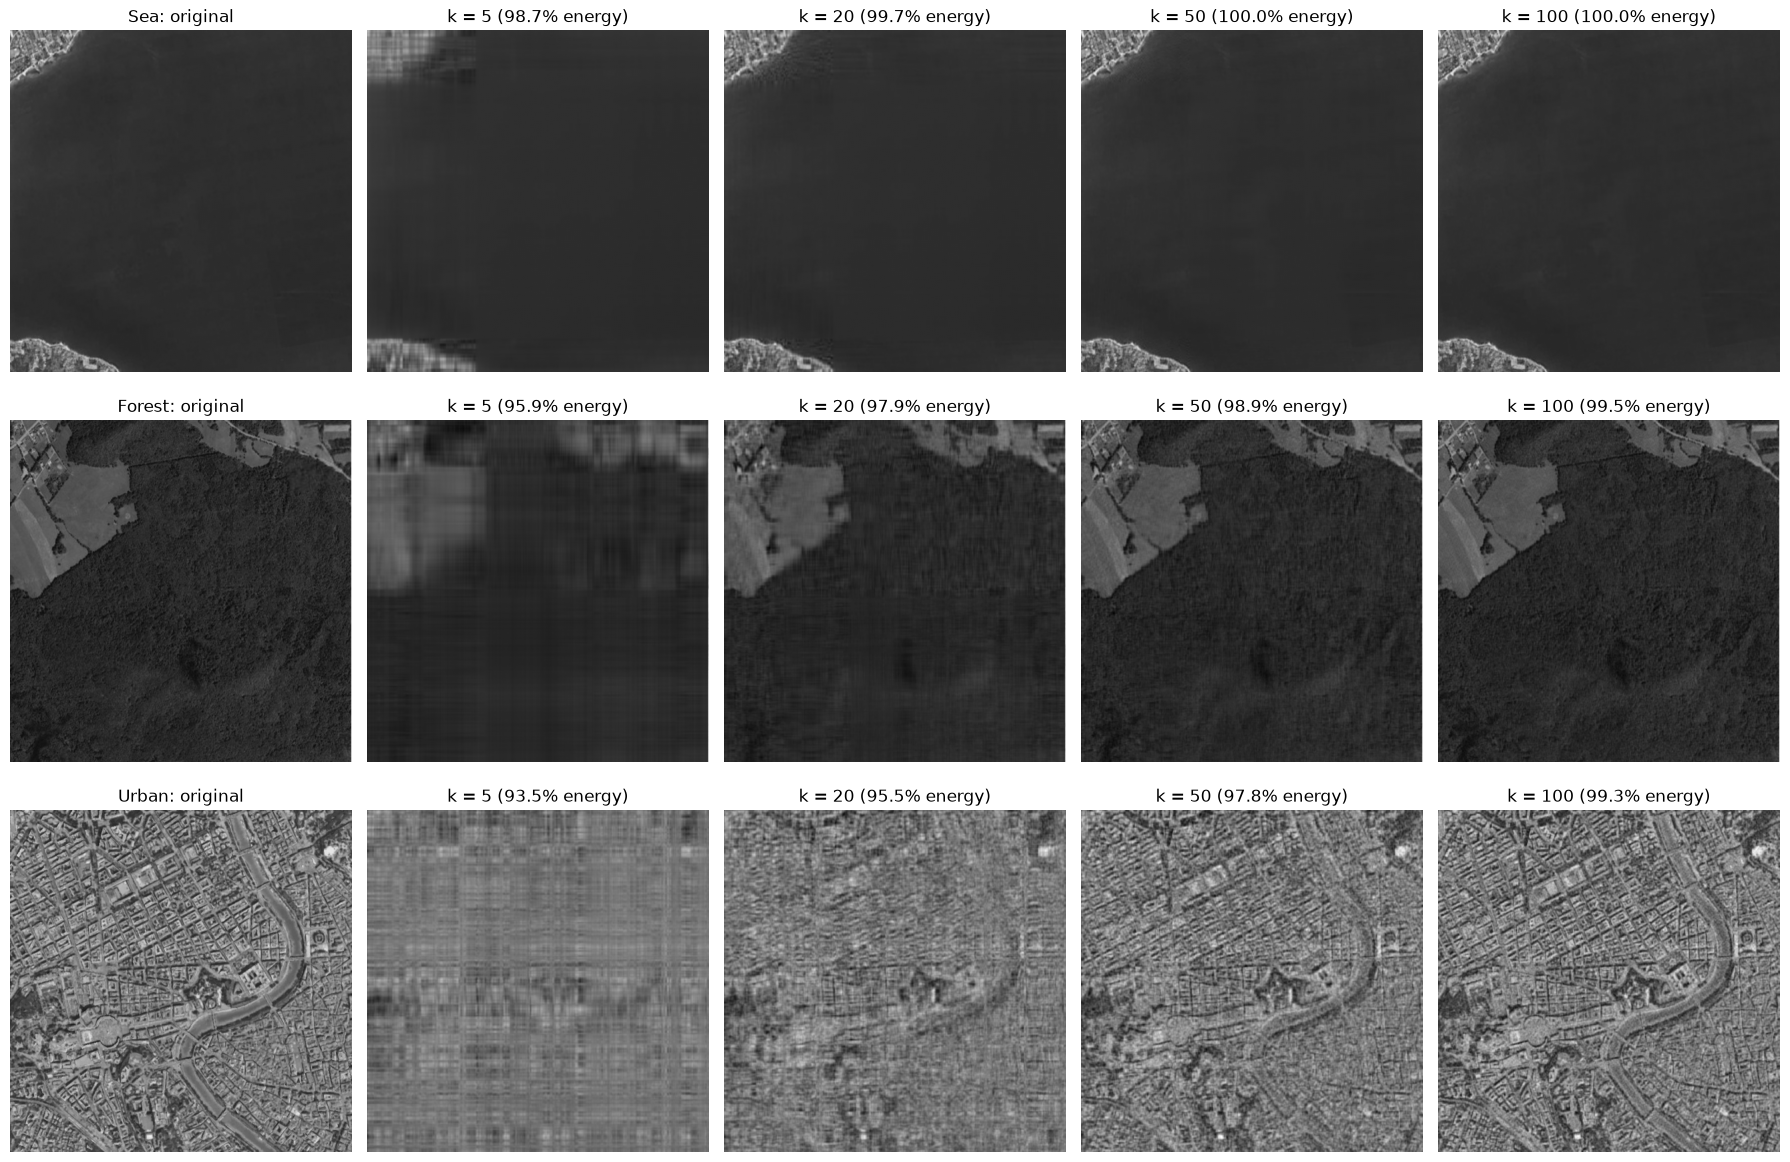

In [25]:
ks = [5, 20, 50, 100]

def reconstruct(U, sigma, Vt, start, stop):
    """Reconstruct an image using singular-value components [start:stop]."""
    return U[:, start:stop] @ np.diag(sigma[start:stop]) @ Vt[start:stop, :]

print("Available images:", list(terrains.keys()))
print("Available SVD results:", list(results.keys()))

fig, axes = plt.subplots(
    len(results), len(ks) + 1,
    figsize=(18, 4 * len(results)),
    squeeze=False
)

for row, (name, result) in enumerate(results.items()):
    image = terrains[name]

    axes[row, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"{name}: original")

    U = result["U"]
    sigma = result["sigma"]
    Vt = result["Vt"]
    energy = result["energy"]

    for col, k in enumerate(ks, start=1):
        k_eff = min(k, len(sigma))

        reconstruction = reconstruct(U, sigma, Vt, 0, k_eff)

        axes[row, col].imshow(
            reconstruction, cmap="gray", vmin=0, vmax=255
        )
        axes[row, col].set_title(
            f"k = {k_eff} ({energy[k_eff - 1] * 100:.1f}% energy)"
        )

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Visual comparison of image reconstruction

The following grid compares each original terrain image with reconstructions using 5, 20, 50, and 100 leading singular-value components.

As *k* increases, the reconstruction generally becomes closer to the original image. Small values of *k* preserve broad patterns but may produce blurred or simplified results. Larger values retain more edges and texture, reducing visible reconstruction errors.

The rate of improvement can differ between terrain types. Smooth or uniform areas may be represented with relatively few components, whereas images containing complex textures and many local details may require more components. The examples allow this tendency to be assessed for the selected sea, forest, and urban images.

## Overall conclusions

1. SVD can approximate a grayscale image using a limited number of singular-value components. The leading components preserve the most significant matrix information.
2. The quality of reconstruction improves as more leading components are included, although the improvement becomes progressively smaller.
3. Starting from a later singular value and omitting the largest components generally does not produce a better overall reconstruction. It may highlight selected details, but important global image information is lost.
4. The number of components required depends on the image content. Sea, forest, and urban scenes have different spatial patterns and textures, so their energy curves and visual reconstruction quality can differ.
5. Cumulative energy thresholds (90%, 95%, and 99%) provide quantitative comparison points, while the reconstruction plots show how those approximations look visually.

The best value of *k* is therefore a compromise between image quality and the number of components used. It should be selected based on both the numerical energy results and the visual appearance of the reconstructed image.